In [14]:
# reading in the data and cleaning it up

import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np


df = pd.read_csv('data.csv')
df['MONTH'] = pd.to_datetime(df['MONTH'], format='%Y / %m')

df.head(-10)

,MONTH,BOROUGH,COMMUNITYDISTRICT,REFUSETONSCOLLECTED,PAPERTONSCOLLECTED,MGPTONSCOLLECTED,RESORGANICSTONS,SCHOOLORGANICTONS,LEAVESORGANICTONS,XMASTREETONS,OTHERORGANICSTONS,BOROUGH_ID
0,2026-06-01,Bronx,1,3713.8,259.1,149.2,24.1,56.8,NaN,NaN,NaN,2
1,2026-06-01,Bronx,2,8137.7,250.3,202.3,16.3,76.8,NaN,NaN,NaN,2
2,2026-06-01,Bronx,3,2402.2,145.9,150.0,23.9,NaN,NaN,NaN,NaN,2
3,2026-06-01,Bronx,4,4353.5,279.9,304.8,29.8,50.6,NaN,NaN,NaN,2
4,2026-06-01,Bronx,5,3725.0,277.8,319.1,25.1,51.7,NaN,NaN,NaN,2
...,...,...,...,...,...,...,...,...,...,...,...,...
25104,1990-08-01,Manhattan,8,3926.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
25105,1990-08-01,Manhattan,10,2021.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
25106,1990-08-01,Manhattan,11,2079.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
25107,1990-08-01,Staten Island,1,5102.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5


In [15]:
window = df[(df['MONTH'] >= '2015-01-01') & (df['MONTH'] <= '2019-12-31')].copy()

model_cols = ['MONTH', 'BOROUGH', 'COMMUNITYDISTRICT', 'REFUSETONSCOLLECTED', 'PAPERTONSCOLLECTED', 'MGPTONSCOLLECTED', 'RESORGANICSTONS']
window = window[model_cols]

print(window.shape)
print(window.isna().sum())
window.head()

(3540, 7)
MONTH                     0
BOROUGH                   0
COMMUNITYDISTRICT         0
REFUSETONSCOLLECTED       0
PAPERTONSCOLLECTED        0
MGPTONSCOLLECTED          0
RESORGANICSTONS        2188
dtype: int64


,MONTH,BOROUGH,COMMUNITYDISTRICT,REFUSETONSCOLLECTED,PAPERTONSCOLLECTED,MGPTONSCOLLECTED,RESORGANICSTONS
4602,2019-12-01,Bronx,1,3101.9,287.2,178.3,3.5
4603,2019-12-01,Bronx,2,8661.5,191.0,247.9,NaN
4604,2019-12-01,Bronx,3,2260.8,142.0,194.0,NaN
4605,2019-12-01,Bronx,4,4036.2,330.3,401.8,12.5
4606,2019-12-01,Bronx,5,3613.5,268.5,347.0,NaN


In [16]:
window_core = window.drop(columns=['RESORGANICSTONS'])
window_core.shape
window_core['month_num'] = window_core['MONTH'].dt.month
window_core['year'] = window_core['MONTH'].dt.year
window_core['quarter'] = window_core['MONTH'].dt.quarter
window_core = window_core.sort_values(['BOROUGH', 'COMMUNITYDISTRICT', 'MONTH']).reset_index(drop=True)

for col in ['REFUSETONSCOLLECTED', 'PAPERTONSCOLLECTED', 'MGPTONSCOLLECTED']:
    window_core[f'{col}_lag1'] = window_core.groupby(['BOROUGH', 'COMMUNITYDISTRICT'])[col].shift(1)
    window_core[f'{col}_lag12'] = window_core.groupby(['BOROUGH', 'COMMUNITYDISTRICT'])[col].shift(12)
    window_core[f'{col}_roll3'] = window_core.groupby(['BOROUGH', 'COMMUNITYDISTRICT'])[col].transform(lambda x: x.shift(1).rolling(3).mean())

print(window_core.shape)
print(window_core.isna().sum())
window_core.head(15)

(3540, 18)
MONTH                          0
BOROUGH                        0
COMMUNITYDISTRICT              0
REFUSETONSCOLLECTED            0
PAPERTONSCOLLECTED             0
MGPTONSCOLLECTED               0
month_num                      0
year                           0
quarter                        0
REFUSETONSCOLLECTED_lag1      59
REFUSETONSCOLLECTED_lag12    708
REFUSETONSCOLLECTED_roll3    177
PAPERTONSCOLLECTED_lag1       59
PAPERTONSCOLLECTED_lag12     708
PAPERTONSCOLLECTED_roll3     177
MGPTONSCOLLECTED_lag1         59
MGPTONSCOLLECTED_lag12       708
MGPTONSCOLLECTED_roll3       177
dtype: int64


,MONTH,BOROUGH,COMMUNITYDISTRICT,REFUSETONSCOLLECTED,PAPERTONSCOLLECTED,MGPTONSCOLLECTED,month_num,year,quarter,REFUSETONSCOLLECTED_lag1,REFUSETONSCOLLECTED_lag12,REFUSETONSCOLLECTED_roll3,PAPERTONSCOLLECTED_lag1,PAPERTONSCOLLECTED_lag12,PAPERTONSCOLLECTED_roll3,MGPTONSCOLLECTED_lag1,MGPTONSCOLLECTED_lag12,MGPTONSCOLLECTED_roll3
0,2015-01-01,Bronx,1,2826.4,192.0,92.0,1,2015,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-02-01,Bronx,1,2445.3,183.7,105.0,2,2015,1,2826.4,NaN,NaN,192.0,NaN,NaN,92.0,NaN,NaN
2,2015-03-01,Bronx,1,3156.4,226.0,114.9,3,2015,1,2445.3,NaN,NaN,183.7,NaN,NaN,105.0,NaN,NaN
3,2015-04-01,Bronx,1,3138.6,214.7,106.6,4,2015,2,3156.4,NaN,2809.366667,226.0,NaN,200.566667,114.9,NaN,103.966667
4,2015-05-01,Bronx,1,3346.9,230.1,101.3,5,2015,2,3138.6,NaN,2913.433333,214.7,NaN,208.133333,106.6,NaN,108.833333
5,2015-06-01,Bronx,1,3791.4,315.4,135.9,6,2015,2,3346.9,NaN,3213.966667,230.1,NaN,223.600000,101.3,NaN,107.600000
6,2015-07-01,Bronx,1,2996.5,216.9,108.5,7,2015,3,3791.4,NaN,3425.633333,315.4,NaN,253.400000,135.9,NaN,114.600000
7,2015-08-01,Bronx,1,2794.3,200.5,116.3,8,2015,3,2996.5,NaN,3378.266667,216.9,NaN,254.133333,108.5,NaN,115.233333
8,2015-09-01,Bronx,1,3248.0,266.6,123.6,9,2015,3,2794.3,NaN,3194.066667,200.5,NaN,244.266667,116.3,NaN,120.233333
9,2015-10-01,Bronx,1,3495.6,245.4,117.8,10,2015,4,3248.0,NaN,3012.933333,266.6,NaN,228.000000,123.6,NaN,116.133333


In [17]:
window_model = window_core.dropna(subset=['REFUSETONSCOLLECTED_lag12', 'PAPERTONSCOLLECTED_lag12', 'MGPTONSCOLLECTED_lag12']).copy()
print(window_model.shape)
window_model['BOROUGH'] = window_model['BOROUGH'].astype('category')
window_model['COMMUNITYDISTRICT'] = window_model['COMMUNITYDISTRICT'].astype('category')

(2832, 18)


In [18]:
print(window_model['MONTH'].min(), window_model['MONTH'].max())


2016-01-01 00:00:00 2019-12-01 00:00:00


In [19]:
cutoff = '2019-01-01'

train = window_model[window_model['MONTH'] < cutoff].copy()
test = window_model[window_model['MONTH'] >= cutoff].copy()

print(f"Train: {train.shape}, from {train['MONTH'].min()} to {train['MONTH'].max()}")
print(f"Test: {test.shape}, from {test['MONTH'].min()} to {test['MONTH'].max()}")

Train: (2124, 18), from 2016-01-01 00:00:00 to 2018-12-01 00:00:00
Test: (708, 18), from 2019-01-01 00:00:00 to 2019-12-01 00:00:00


MAE: 204.0 tons
RMSE: 278.7 tons
Mean actual value: 4215.3 tons
Naive MAE: 268.5 tons
Naive RMSE: 357.7 tons
XGBoost improvement: 24.0%


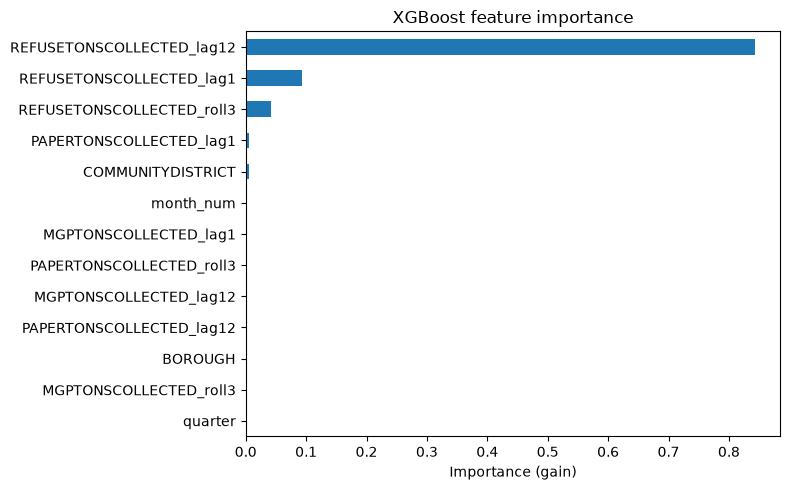

REFUSETONSCOLLECTED_lag12    0.842465
REFUSETONSCOLLECTED_lag1     0.093435
REFUSETONSCOLLECTED_roll3    0.041244
PAPERTONSCOLLECTED_lag1      0.004741
COMMUNITYDISTRICT            0.004711
month_num                    0.002521
MGPTONSCOLLECTED_lag1        0.002276
PAPERTONSCOLLECTED_roll3     0.001967
MGPTONSCOLLECTED_lag12       0.001801
PAPERTONSCOLLECTED_lag12     0.001783
BOROUGH                      0.001560
MGPTONSCOLLECTED_roll3       0.001496
quarter                      0.000000
dtype: float32


In [20]:
# training the model for refuse collection prediction
feature_cols = ['BOROUGH', 'COMMUNITYDISTRICT', 'month_num', 'quarter',
                 'REFUSETONSCOLLECTED_lag1', 'REFUSETONSCOLLECTED_lag12', 'REFUSETONSCOLLECTED_roll3',
                 'PAPERTONSCOLLECTED_lag1', 'PAPERTONSCOLLECTED_lag12', 'PAPERTONSCOLLECTED_roll3',
                 'MGPTONSCOLLECTED_lag1', 'MGPTONSCOLLECTED_lag12', 'MGPTONSCOLLECTED_roll3']

X_train = train[feature_cols]
X_test = test[feature_cols]

y_train_refuse = train['REFUSETONSCOLLECTED']
y_test_refuse = test['REFUSETONSCOLLECTED']

y_train_paper = train['PAPERTONSCOLLECTED']
y_test_paper = test['PAPERTONSCOLLECTED']

y_train_mgp = train['MGPTONSCOLLECTED']
y_test_mgp = test['MGPTONSCOLLECTED']


model_refuse = xgb.XGBRegressor(
    enable_categorical=True,
    tree_method='hist',
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    random_state=42
)

model_refuse.fit(X_train, y_train_refuse)

preds_refuse = model_refuse.predict(X_test)

mae = mean_absolute_error(y_test_refuse, preds_refuse)
mae = mean_absolute_error(y_test_refuse, preds_refuse)
mse = mean_squared_error(y_test_refuse, preds_refuse)
rmse = np.sqrt(mse)


print(f"MAE: {mae:.1f} tons")
print(f"RMSE: {rmse:.1f} tons")
print(f"Mean actual value: {y_test_refuse.mean():.1f} tons")

naive_preds = test['REFUSETONSCOLLECTED_lag1']
naive_mae = mean_absolute_error(y_test_refuse, naive_preds)
naive_rmse = np.sqrt(mean_squared_error(y_test_refuse, naive_preds))

print(f"Naive MAE: {naive_mae:.1f} tons")
print(f"Naive RMSE: {naive_rmse:.1f} tons")
print(f"XGBoost improvement: {(1 - mae/naive_mae) * 100:.1f}%")

#SHAP analysis for refuse model
importances = pd.Series(
    model_refuse.feature_importances_, index=feature_cols).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind="barh", ax=ax, color="tab:blue")
ax.set_xlabel("Importance (gain)")
ax.set_title("XGBoost feature importance")
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False))

In [21]:
# tuning original refuse model with hyperparameter tuning
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

tscv = TimeSeriesSplit(n_splits=3)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1]
}

base_model = xgb.XGBRegressor(enable_categorical=True, tree_method='hist', random_state=42)

grid_search_ts = GridSearchCV(
    base_model, param_grid,
    scoring='neg_mean_absolute_error',
    cv=tscv
)

grid_search_ts.fit(X_train, y_train_refuse)

print("Best params (time-aware):", grid_search_ts.best_params_)
print("Best CV MAE (time-aware):", -grid_search_ts.best_score_)

Best params (time-aware): {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
Best CV MAE (time-aware): 247.30686470410095


MAE feature selection: 199.7 tons
RMSE: 282.5 tons
Mean actual value: 4215.3 tons
Naive MAE: 268.5 tons
Naive RMSE: 357.7 tons
XGBoost improvement: 25.6%
feature selection improvement: 2.1%
Accuracy Feature Selection: 95.3%
Accuracy Without Feature Selection: 95.2%


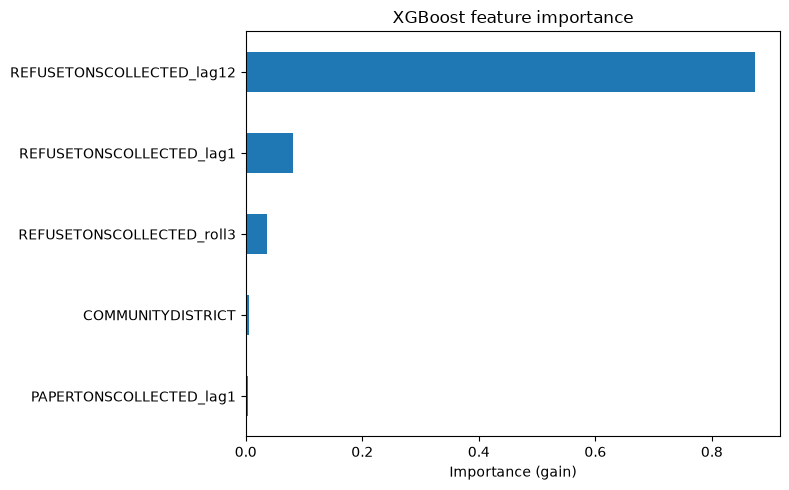

REFUSETONSCOLLECTED_lag12    0.873284
REFUSETONSCOLLECTED_lag1     0.080712
REFUSETONSCOLLECTED_roll3    0.036642
COMMUNITYDISTRICT            0.005160
PAPERTONSCOLLECTED_lag1      0.004202
dtype: float32


In [22]:
#refuse model without meaningless features
refuse_feature_cols = ['COMMUNITYDISTRICT', 'REFUSETONSCOLLECTED_lag1',
                       'REFUSETONSCOLLECTED_lag12', 'REFUSETONSCOLLECTED_roll3', 'PAPERTONSCOLLECTED_lag1']

X_train_selec = train[refuse_feature_cols]
X_test_selec = test[refuse_feature_cols]

y_train_refuse = train['REFUSETONSCOLLECTED']
y_test_refuse = test['REFUSETONSCOLLECTED']



model_refuse = xgb.XGBRegressor(
    enable_categorical=True,
    tree_method='hist',
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    random_state=42
)

model_refuse.fit(X_train_selec, y_train_refuse)

preds_refuse = model_refuse.predict(X_test_selec)

mae_feature_selec = mean_absolute_error(y_test_refuse, preds_refuse)
mae_feature_selec = mean_absolute_error(y_test_refuse, preds_refuse)
mse = mean_squared_error(y_test_refuse, preds_refuse)
rmse = np.sqrt(mse)


print(f"MAE feature selection: {mae_feature_selec:.1f} tons")
print(f"RMSE: {rmse:.1f} tons")
print(f"Mean actual value: {y_test_refuse.mean():.1f} tons")

naive_preds = test['REFUSETONSCOLLECTED_lag1']
naive_mae = mean_absolute_error(y_test_refuse, naive_preds)
naive_rmse = np.sqrt(mean_squared_error(y_test_refuse, naive_preds))

print(f"Naive MAE: {naive_mae:.1f} tons")
print(f"Naive RMSE: {naive_rmse:.1f} tons")
print(f"XGBoost improvement: {(1 - mae_feature_selec/naive_mae) * 100:.1f}%")
print(f"feature selection improvement: {(1 - mae_feature_selec/mae) * 100:.1f}%")
print(f"Accuracy Feature Selection: {(1 - mae_feature_selec/y_test_refuse.mean()) * 100:.1f}%")
print(f"Accuracy Without Feature Selection: {(1 - mae/y_test_refuse.mean()) * 100:.1f}%")





#SHAP analysis for refuse model
importances = pd.Series(
    model_refuse.feature_importances_, index=refuse_feature_cols).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind="barh", ax=ax, color="tab:blue")
ax.set_xlabel("Importance (gain)")
ax.set_title("XGBoost feature importance")
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False))

In [23]:
print(y_train_paper)

12      204.1
13      252.2
14      242.8
15      234.7
16      236.4
        ...  
3523    801.7
3524    770.2
3525    777.8
3526    854.9
3527    919.0
Name: PAPERTONSCOLLECTED, Length: 2124, dtype: float64


Paper MAE: 31.5, RMSE: 42.7, Mean: 456.5
Paper Naive MAE: 41.9
Improvement: 24.7%


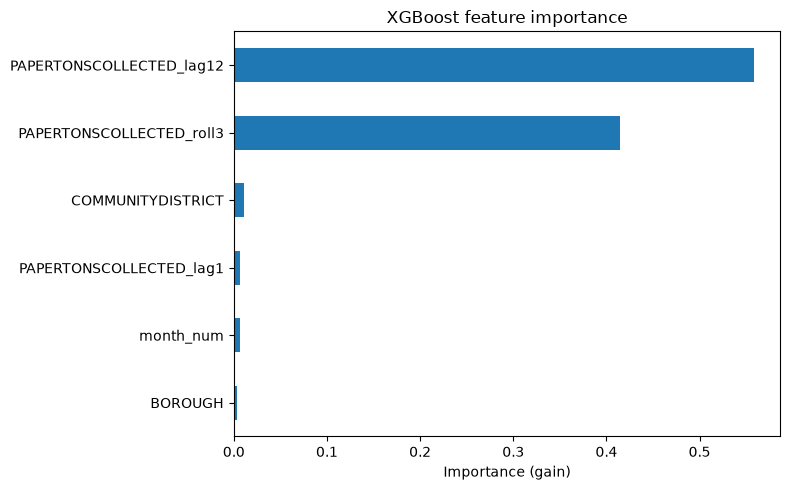

PAPERTONSCOLLECTED_lag12    0.558425
PAPERTONSCOLLECTED_roll3    0.414322
COMMUNITYDISTRICT           0.010584
PAPERTONSCOLLECTED_lag1     0.006778
month_num                   0.006360
BOROUGH                     0.003531
dtype: float32


In [24]:
#training the model for paper collection prediction

paper_feature_cols = ['BOROUGH', 'COMMUNITYDISTRICT', 'month_num',
                    'PAPERTONSCOLLECTED_lag1', 'PAPERTONSCOLLECTED_lag12', 'PAPERTONSCOLLECTED_roll3']
X_train_paper = train[paper_feature_cols]
X_test_paper = test[paper_feature_cols]

model_paper = xgb.XGBRegressor(
    enable_categorical=True, tree_method='hist',
    n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42
)
model_paper.fit(X_train_paper, y_train_paper)
preds_paper = model_paper.predict(X_test_paper)

mae_paper = mean_absolute_error(y_test_paper, preds_paper)
rmse_paper = np.sqrt(mean_squared_error(y_test_paper, preds_paper))
naive_paper = mean_absolute_error(y_test_paper, test['PAPERTONSCOLLECTED_lag1'])

print(f"Paper MAE: {mae_paper:.1f}, RMSE: {rmse_paper:.1f}, Mean: {y_test_paper.mean():.1f}")
print(f"Paper Naive MAE: {naive_paper:.1f}")
print(f"Improvement: {(1 - mae_paper/naive_paper)*100:.1f}%")

#SHAP analysis for paper model
importances = pd.Series(
    model_paper.feature_importances_, index=paper_feature_cols).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind="barh", ax=ax, color="tab:blue")
ax.set_xlabel("Importance (gain)")
ax.set_title("XGBoost feature importance")
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False))

MGP MAE: 24.4, RMSE: 31.9, Mean: 427.7
MGP Naive MAE: 38.9
Improvement: 37.4%


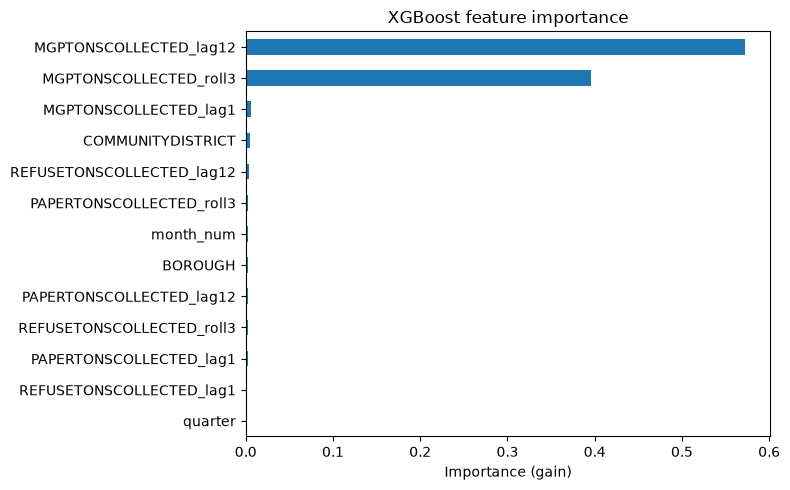

MGPTONSCOLLECTED_lag12       0.572487
MGPTONSCOLLECTED_roll3       0.395513
MGPTONSCOLLECTED_lag1        0.005939
COMMUNITYDISTRICT            0.005397
REFUSETONSCOLLECTED_lag12    0.003956
PAPERTONSCOLLECTED_roll3     0.002878
month_num                    0.002744
BOROUGH                      0.002554
PAPERTONSCOLLECTED_lag12     0.002435
REFUSETONSCOLLECTED_roll3    0.002309
PAPERTONSCOLLECTED_lag1      0.002152
REFUSETONSCOLLECTED_lag1     0.001636
quarter                      0.000000
dtype: float32


In [25]:
# training the model for MGP (Mixed Glass Plastic) collection prediction
mgp_feature_cols = feature_cols.copy()

X_train_mgp = train[mgp_feature_cols]
X_test_mgp = test[mgp_feature_cols]

model_mgp = xgb.XGBRegressor(
    enable_categorical=True, tree_method='hist',
    n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42
)
model_mgp.fit(X_train_mgp, y_train_mgp)
preds_mgp = model_mgp.predict(X_test_mgp)

mae_mgp = mean_absolute_error(y_test_mgp, preds_mgp)
rmse_mgp = np.sqrt(mean_squared_error(y_test_mgp, preds_mgp))
naive_mgp = mean_absolute_error(y_test_mgp, test['MGPTONSCOLLECTED_lag1'])

print(f"MGP MAE: {mae_mgp:.1f}, RMSE: {rmse_mgp:.1f}, Mean: {y_test_mgp.mean():.1f}")
print(f"MGP Naive MAE: {naive_mgp:.1f}")
print(f"Improvement: {(1 - mae_mgp/naive_mgp)*100:.1f}%")

#SHAP analysis for MGP model
importances = pd.Series(
    model_mgp.feature_importances_, index=mgp_feature_cols).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind="barh", ax=ax, color="tab:blue")
ax.set_xlabel("Importance (gain)")
ax.set_title("XGBoost feature importance")
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False))

MAE without lag12: 25.3 (vs 24.4 with lag12)
Improvement: 34.9%
Improvement: 3.9%


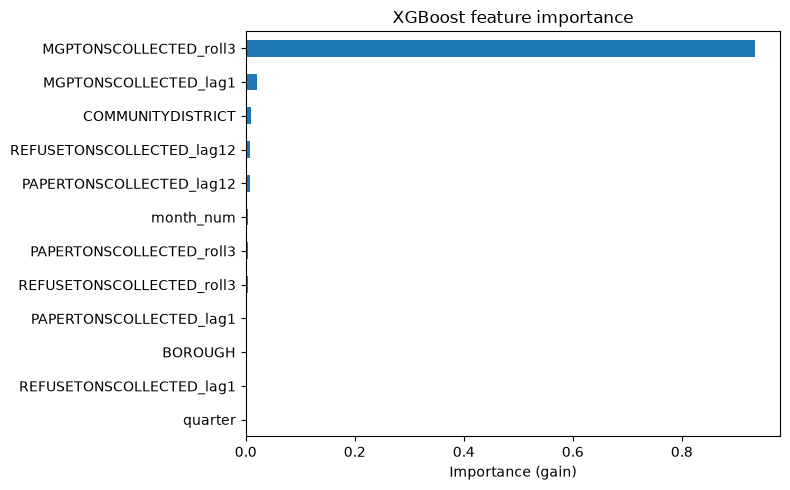

MGPTONSCOLLECTED_roll3       0.933443
MGPTONSCOLLECTED_lag1        0.020663
COMMUNITYDISTRICT            0.008856
REFUSETONSCOLLECTED_lag12    0.007566
PAPERTONSCOLLECTED_lag12     0.007234
month_num                    0.004883
PAPERTONSCOLLECTED_roll3     0.004883
REFUSETONSCOLLECTED_roll3    0.003763
PAPERTONSCOLLECTED_lag1      0.003245
BOROUGH                      0.003132
REFUSETONSCOLLECTED_lag1     0.002331
quarter                      0.000000
dtype: float32


In [26]:
#MGP with no lag 12 feature, to see if it requires a year of data to be accurate, or if it can be trained on a shorter time frame.
feature_cols_no_lag12 = [c for c in feature_cols if c != 'MGPTONSCOLLECTED_lag12']

model_mgp_no12 = xgb.XGBRegressor(
    enable_categorical=True, tree_method='hist',
    n_estimators=200, max_depth=5, learning_rate=0.05, random_state=42
)
model_mgp_no12.fit(train[feature_cols_no_lag12], y_train_mgp)
preds_no12 = model_mgp_no12.predict(test[feature_cols_no_lag12])

mae_no12 = mean_absolute_error(y_test_mgp, preds_no12)
print(f"MAE without lag12: {mae_no12:.1f} (vs {mae_mgp:.1f} with lag12)")
print(f"Improvement: {(1 - mae_no12/naive_mgp)*100:.1f}%")
print(f"Improvement: {(1 - mae_mgp/mae_no12)*100:.1f}%")


importances = pd.Series(
    model_mgp_no12.feature_importances_, index=feature_cols_no_lag12).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind="barh", ax=ax, color="tab:blue")
ax.set_xlabel("Importance (gain)")
ax.set_title("XGBoost feature importance")
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False))

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

categorical_cols = ['BOROUGH', 'COMMUNITYDISTRICT']
numeric_cols = [c for c in feature_cols if c not in categorical_cols]

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
], remainder='passthrough')

lr_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', LinearRegression())
])

lr_pipeline.fit(X_train, y_train_refuse)
preds_lr = lr_pipeline.predict(X_test)

mae_lr = mean_absolute_error(y_test_refuse, preds_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test_refuse, preds_lr))

print(f"Linear Regression MAE: {mae_lr:.1f} tons")
print(f"Linear Regression RMSE: {rmse_lr:.1f} tons")
print(f"Improvement vs naive: {(1 - mae_lr/naive_mae)*100:.1f}%")

Linear Regression MAE: 199.7 tons
Linear Regression RMSE: 268.9 tons
Improvement vs naive: 25.6%


In [28]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

nn_pipeline = Pipeline([
    ('prep', preprocessor),
    ('scale', StandardScaler(with_mean=False)),  # with_mean=False needed after one-hot encoding
    ('model', MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=2000, random_state=42))
])

nn_pipeline.fit(X_train, y_train_refuse)
preds_nn = nn_pipeline.predict(X_test)

mae_nn = mean_absolute_error(y_test_refuse, preds_nn)
rmse_nn = np.sqrt(mean_squared_error(y_test_refuse, preds_nn))

print(f"Neural Network MAE: {mae_nn:.1f} tons")
print(f"Neural Network RMSE: {rmse_nn:.1f} tons")
print(f"Improvement vs naive: {(1 - mae_nn/naive_mae)*100:.1f}%")

Neural Network MAE: 204.9 tons
Neural Network RMSE: 272.6 tons
Improvement vs naive: 23.7%


In [29]:
categorical_cols_selected = ['COMMUNITYDISTRICT']

preprocessor_selected = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols_selected)
], remainder='passthrough')

lr_pipeline_selected = Pipeline([
    ('prep', preprocessor_selected),
    ('model', LinearRegression())
])

X_train_selected = train[refuse_feature_cols]
X_test_selected = test[refuse_feature_cols]

lr_pipeline_selected.fit(X_train_selected, y_train_refuse)
preds_lr_selected = lr_pipeline_selected.predict(X_test_selected)

mae_lr_selected = mean_absolute_error(y_test_refuse, preds_lr_selected)
rmse_lr_selected = np.sqrt(mean_squared_error(y_test_refuse, preds_lr_selected))

print(f"Linear Regression (selected features) MAE: {mae_lr_selected:.1f} tons")
print(f"Linear Regression (selected features) RMSE: {rmse_lr_selected:.1f} tons")

Linear Regression (selected features) MAE: 204.1 tons
Linear Regression (selected features) RMSE: 273.5 tons


## Model Selection Findings

Across feature selection, standard cross-validated hyperparameter tuning, and 
time-series-aware tuning, the original untuned model (all 13 features, default 
hyperparameters) remained the strongest performer for refuse when evaluated on 
the genuine held-out test year. Neither tuning approach improved on this baseline: 
standard cross-validation is not time-aware and risks leaking future information 
into validation folds, while `TimeSeriesSplit`, though methodologically more 
appropriate, was constrained by the limited data available in its earliest folds 
given the dataset's ~4-year span. Other targets (paper, MGP) were not put through 
the same tuning process in this pass, but the same conclusion can reasonably be 
assumed to extend to them; this should be confirmed directly once real pilot data 
is available.

On average, the model's predictions are within roughly 5% of actual tonnage.

The 12-month lag feature (`lag12`) is the dominant predictor across all three 
waste streams, suggesting that year-over-year seasonality is the strongest signal 
in the data. However, an ablation test on MGP, removing `lag12` entirely, 
increased MAE by less than 4%, indicating substantial overlap between `lag12`, 
`roll3` (3-month rolling average), and `lag1`. In practice, the model does not 
appear to depend critically on a full year of history: three months of pilot 
data, or potentially less at a more granular (e.g. weekly) resolution, may be 
enough to produce reasonably accurate forecasts.

The features with low individual importance still contribute meaningfully in 
aggregate. Restricting the refuse model to only its five most important features 
produced a small improvement in MAE (204.0 → 199.7 tons, roughly 2%) but a 
slight *increase* in RMSE (278.7 → 282.5 tons). Since RMSE penalises large errors 
more heavily than MAE, this suggests the lower-importance features were providing 
some robustness against outlier months, even though they contribute little to 
typical-case accuracy. Whether this trade-off is worth making depends on the 
intended use of the forecast, tighter average accuracy favours dropping them, 
while robustness against a costly large miss (e.g. a recycler capacity 
commitment) favours keeping them.

### Comparing Model Types

XGBoost was not the only model tested. Linear regression and a small neural 
network (MLP) were also evaluated on the same refuse target, using the same 
train/test split, for a fair comparison:

| Model | MAE (tons) | RMSE (tons) | Improvement vs naive |
|---|---|---|---|
| **Linear regression (all features)** | **199.7** | **268.9** | **25.6%** |
| XGBoost (feature-selected) | 199.7 | 282.5 | 25.6% |
| XGBoost (all features) | 204.0 | 278.7 | 24.0% |
| Linear regression (selected features) | 204.1 | 273.5 | 23.8% |
| Neural network (MLP) | 204.9 | 272.6 | 23.7% |

Linear regression with the full feature set performed best overall, matching 
XGBoost's best MAE and beating it on RMSE, despite being a far simpler model. 
This is consistent with the earlier finding that `lag12` alone captures most of 
the predictive signal, the underlying relationship appears close to linear, so 
the added flexibility of a tree-based model wasn't necessary here.

Interestingly, feature selection had opposite effects depending on model type: 
it slightly improved XGBoost (204.0 → 199.7 MAE) but slightly worsened linear 
regression (199.7 → 204.1 MAE). This is likely due to multicollinearity between 
the lag and rolling-average features, they carry overlapping information. 
XGBoost can effectively route around redundant features during tree-splitting, 
so trimming them removes mostly noise. Linear regression has no equivalent 
mechanism; it extracts and combines some genuine signal from every feature it's 
given, so removing even a low-importance feature discards a small amount of real 
information. This means feature selection is a model-specific decision, not a 
universal improvement.

The neural network underperformed both, most likely due to the limited size of 
the dataset (~2,800 rows), MLPs typically need substantially more data than 
this to outperform simpler methods.

Overall, linear regression with the full feature set is the recommended model 
for this dataset: it is the most accurate by RMSE, ties for best MAE, and is 
simpler, faster, and easier to explain to non-technical stakeholders than 
XGBoost or a neural network.

In [30]:
# Linear regression for paper collection prediction
X_train_paper_full = train[feature_cols]
X_test_paper_full = test[feature_cols]

lr_pipeline_paper = Pipeline([
    ('prep', preprocessor),
    ('model', LinearRegression())
])

lr_pipeline_paper.fit(X_train_paper_full, y_train_paper)
preds_lr_paper = lr_pipeline_paper.predict(X_test_paper_full)

mae_lr_paper = mean_absolute_error(y_test_paper, preds_lr_paper)
rmse_lr_paper = np.sqrt(mean_squared_error(y_test_paper, preds_lr_paper))

print(f"Paper Linear Regression MAE: {mae_lr_paper:.1f} tons")
print(f"Paper Linear Regression RMSE: {rmse_lr_paper:.1f} tons")
print(f"Improvement vs naive: {(1 - mae_lr_paper/naive_paper)*100:.1f}%")
print(f"(XGBoost comparison — MAE: {mae_paper:.1f}, RMSE: {rmse_paper:.1f})")

Paper Linear Regression MAE: 30.0 tons
Paper Linear Regression RMSE: 38.7 tons
Improvement vs naive: 28.4%
(XGBoost comparison — MAE: 31.5, RMSE: 42.7)


In [31]:
# Linear regression for MGP collection prediction
X_train_mgp_full = train[feature_cols]
X_test_mgp_full = test[feature_cols]

lr_pipeline_mgp = Pipeline([
    ('prep', preprocessor),
    ('model', LinearRegression())
])

lr_pipeline_mgp.fit(X_train_mgp_full, y_train_mgp)
preds_lr_mgp = lr_pipeline_mgp.predict(X_test_mgp_full)

mae_lr_mgp = mean_absolute_error(y_test_mgp, preds_lr_mgp)
rmse_lr_mgp = np.sqrt(mean_squared_error(y_test_mgp, preds_lr_mgp))

print(f"MGP Linear Regression MAE: {mae_lr_mgp:.1f} tons")
print(f"MGP Linear Regression RMSE: {rmse_lr_mgp:.1f} tons")
print(f"Improvement vs naive: {(1 - mae_lr_mgp/naive_mgp)*100:.1f}%")
print(f"(XGBoost comparison — MAE: {mae_mgp:.1f}, RMSE: {rmse_mgp:.1f})")

MGP Linear Regression MAE: 27.4 tons
MGP Linear Regression RMSE: 34.5 tons
Improvement vs naive: 29.6%
(XGBoost comparison — MAE: 24.4, RMSE: 31.9)


In [36]:
# Standardized linear regression for MGP
preprocessor_mgp_scaled = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
    ('num', StandardScaler(), numeric_cols)
])

lr_pipeline_mgp_scaled = Pipeline([
    ('prep', preprocessor_mgp_scaled),
    ('model', LinearRegression())
])

lr_pipeline_mgp_scaled.fit(X_train_mgp_full, y_train_mgp)

feature_names_mgp_scaled = lr_pipeline_mgp_scaled.named_steps['prep'].get_feature_names_out()
coefs_mgp_scaled = pd.Series(
    lr_pipeline_mgp_scaled.named_steps['model'].coef_, index=feature_names_mgp_scaled
).sort_values(key=abs, ascending=False)

print(coefs_mgp_scaled)

num__MGPTONSCOLLECTED_roll3       100.588745
num__MGPTONSCOLLECTED_lag12        63.407933
num__REFUSETONSCOLLECTED_roll3    -48.318484
num__REFUSETONSCOLLECTED_lag12     31.652301
num__REFUSETONSCOLLECTED_lag1      18.528077
num__PAPERTONSCOLLECTED_lag12       9.965326
cat__BOROUGH_Manhattan             -7.091281
num__PAPERTONSCOLLECTED_lag1       -6.884545
cat__COMMUNITYDISTRICT_18           6.660086
cat__COMMUNITYDISTRICT_6           -5.377994
cat__COMMUNITYDISTRICT_11          -5.275365
cat__COMMUNITYDISTRICT_14          -5.057244
cat__COMMUNITYDISTRICT_17           4.974666
cat__COMMUNITYDISTRICT_7            4.870226
cat__BOROUGH_Queens                 4.766959
cat__COMMUNITYDISTRICT_12           4.238248
cat__BOROUGH_Staten Island          3.898651
cat__COMMUNITYDISTRICT_8           -3.760544
num__quarter                       -3.703756
cat__COMMUNITYDISTRICT_2           -3.427176
num__MGPTONSCOLLECTED_lag1         -3.027434
cat__COMMUNITYDISTRICT_13           2.843007
cat__BOROU

In [38]:
# Group dummies back to parent feature
coef_df_mgp = coefs_mgp_scaled.abs().reset_index()
coef_df_mgp.columns = ['feature', 'abs_coef']

coef_df_mgp['parent'] = coef_df_mgp['feature'].apply(parent_feature)  # reuse the function from before

grouped_mgp = coef_df_mgp.groupby('parent')['abs_coef'].max().sort_values(ascending=False)
print(grouped_mgp)

parent
MGPTONSCOLLECTED_roll3       100.588745
MGPTONSCOLLECTED_lag12        63.407933
REFUSETONSCOLLECTED_roll3     48.318484
REFUSETONSCOLLECTED_lag12     31.652301
REFUSETONSCOLLECTED_lag1      18.528077
PAPERTONSCOLLECTED_lag12       9.965326
BOROUGH                        7.091281
PAPERTONSCOLLECTED_lag1        6.884545
COMMUNITYDISTRICT              6.660086
quarter                        3.703756
MGPTONSCOLLECTED_lag1          3.027434
month_num                      1.854824
PAPERTONSCOLLECTED_roll3       1.326573
Name: abs_coef, dtype: float64


In [41]:
mgp_lr_feature_cols_selected = [
    'MGPTONSCOLLECTED_roll3', 'MGPTONSCOLLECTED_lag12',
    'REFUSETONSCOLLECTED_roll3', 'REFUSETONSCOLLECTED_lag12',
    'REFUSETONSCOLLECTED_lag1', 'PAPERTONSCOLLECTED_lag1',
    'PAPERTONSCOLLECTED_lag12', 'BOROUGH', 'COMMUNITYDISTRICT'
]

X_train_mgp_lr_sel = train[mgp_lr_feature_cols_selected]
X_test_mgp_lr_sel = test[mgp_lr_feature_cols_selected]

categorical_cols_mgp_sel = ['BOROUGH', 'COMMUNITYDISTRICT']

preprocessor_mgp_lr_sel = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols_mgp_sel)
], remainder='passthrough')

lr_pipeline_mgp_sel = Pipeline([
    ('prep', preprocessor_mgp_lr_sel),
    ('model', LinearRegression())
])

lr_pipeline_mgp_sel.fit(X_train_mgp_lr_sel, y_train_mgp)
preds_lr_mgp_sel = lr_pipeline_mgp_sel.predict(X_test_mgp_lr_sel)

mae_lr_mgp_sel = mean_absolute_error(y_test_mgp, preds_lr_mgp_sel)
rmse_lr_mgp_sel = np.sqrt(mean_squared_error(y_test_mgp, preds_lr_mgp_sel))

print(f"MGP LR (9-feature coef-selected) MAE: {mae_lr_mgp_sel:.1f}, RMSE: {rmse_lr_mgp_sel:.1f}")
print(f"MGP LR (full features)          MAE: {mae_lr_mgp:.1f}, RMSE: {rmse_lr_mgp:.1f}")
print(f"MGP XGBoost (full)              MAE: {mae_mgp:.1f}, RMSE: {rmse_mgp:.1f}")

MGP LR (9-feature coef-selected) MAE: 27.4, RMSE: 34.5
MGP LR (full features)          MAE: 27.4, RMSE: 34.5
MGP XGBoost (full)              MAE: 24.4, RMSE: 31.9
